# Lock-free SPSC queue latency analysis

This notebook analyzes the `latency_throughput_buffer_<size>.csv` outputs generated by the harness. Results are expected in `/results/<variant>/`.

It provides:
- one box plot per queue variant across all buffer sizes,
- box plots comparing all variants at the smallest and largest buffer sizes,
- latency distribution overlays for each of the five buffer sizes.


In [3]:
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')


In [4]:
DATA_DIR = Path('results')
if not DATA_DIR.exists() and Path('/results').exists():
    DATA_DIR = Path('/results')
BUFFER_SIZES = [2, 4, 16, 4096, 65536]
required_columns = {'PushTimestamp', 'PopTimestamp'}

def csv_sources(data_dir):
    pattern = re.compile(r'^latency_throughput_buffer_(\d+)\.csv$')
    flat_pattern = re.compile(r'^(.+)_latency_throughput_buffer_(\d+)\.csv$')

    for csv_path in sorted(data_dir.glob('*/latency_throughput_buffer_*.csv')):
        match = pattern.match(csv_path.name)
        if match:
            yield csv_path.parent.name, int(match.group(1)), csv_path

    for csv_path in sorted(data_dir.glob('*_latency_throughput_buffer_*.csv')):
        match = flat_pattern.match(csv_path.name)
        if match:
            yield match.group(1), int(match.group(2)), csv_path

rows = []
for variant, buffer_size, csv_path in csv_sources(DATA_DIR):
    frame = pd.read_csv(csv_path)
    missing_columns = required_columns - set(frame.columns)
    if missing_columns:
        raise ValueError(f'{csv_path} is missing columns: {sorted(missing_columns)}')

    frame['PushTimestamp'] = pd.to_numeric(frame['PushTimestamp'], errors='coerce')
    frame['PopTimestamp'] = pd.to_numeric(frame['PopTimestamp'], errors='coerce')
    frame = frame.dropna(subset=['PushTimestamp', 'PopTimestamp']).copy()
    frame['latency_us'] = (frame['PopTimestamp'] - frame['PushTimestamp']) * 1_000_000
    frame = frame[frame['latency_us'] >= 0].copy()
    frame['variant'] = variant
    frame['buffer_size'] = buffer_size
    frame['memory_model'] = 'seq_cst' if variant.endswith('-seq_cst') else 'acq_rel'
    frame['base_variant'] = variant.removesuffix('-seq_cst')
    rows.append(frame[['variant', 'base_variant', 'memory_model', 'buffer_size', 'latency_us']])

if not rows:
    raise FileNotFoundError(f'No latency_throughput_buffer_<size>.csv files found in {DATA_DIR.resolve()}')

latencies = pd.concat(rows, ignore_index=True)
available_buffer_sizes = [size for size in BUFFER_SIZES if size in latencies['buffer_size'].unique()]
if not available_buffer_sizes:
    raise ValueError(f'No expected buffer sizes {BUFFER_SIZES} were found in {DATA_DIR.resolve()}')

latencies.head()


,variant,base_variant,memory_model,buffer_size,latency_us
0,0-naive,0-naive,acq_rel,16,1.423001
1,0-naive,0-naive,acq_rel,16,0.271000
2,0-naive,0-naive,acq_rel,16,0.832000
3,0-naive,0-naive,acq_rel,16,0.462000
4,0-naive,0-naive,acq_rel,16,0.782000


In [5]:
preferred_base_order = ['0-naive', '1-padding_without_cached_indices', '2-cached_indices_without_padding', '1-cached_indices_and_padding', '2-bitwise_modulus']
base_variants = sorted(latencies['base_variant'].unique(), key=lambda value: (value not in preferred_base_order, preferred_base_order.index(value) if value in preferred_base_order else value))
variant_order = [variant for base in base_variants for variant in (base, f'{base}-seq_cst') if variant in latencies['variant'].values]

summary = latencies.groupby(['variant', 'buffer_size'])['latency_us'].describe(percentiles=[0.5, 0.9, 0.99])
summary


count         mean  \
variant                                  buffer_size                        
0-naive                                  2            1049.0     0.431986   
                                         4            1049.0     0.385967   
                                         16           1049.0     0.624837   
                                         4096         1049.0    15.331067   
                                         65536        1049.0     9.066915   
0-naive-seq_cst                          2            1049.0     0.387440   
                                         4            1049.0     0.493043   
                                         16           1049.0     0.695932   
                                         4096         1049.0   474.599644   
                                         65536        1049.0   115.850050   
1-cached_indices_and_padding             2            1049.0     0.391710   
                                         4            1049.0     0.277247   
                                         16           1049.0     0.315205   
                                         4096         1049.0     2.119495   
                                         65536        1049.0     2.477062   
1-cached_indices_and_padding-seq_cst     2            1049.0     0.345679   
                                         4            1049.0     0.485381   
                                         16           1049.0     0.838919   
                                         4096         1049.0     8.761645   
                                         65536        1049.0    15.031682   
1-padding_without_cached_indices         2            1049.0     0.362405   
                                         4            1049.0     0.332862   
                                         16           1049.0     0.256496   
                                         4096         1049.0   157.287434   
                                         65536        1049.0  2115.758101   
1-padding_without_cached_indices-seq_cst 2            1049.0     0.382845   
                                         4            1049.0     0.460623   
                                         16           1049.0     0.683298   
                                         4096         1049.0    33.142699   
                                         65536        1049.0  6106.834825   
2-bitwise_modulus                        2            1049.0     0.411199   
                                         4            1049.0     0.348044   
                                         16           1049.0     0.593797   
                                         4096         1049.0    32.202526   
                                         65536        1049.0   189.318009   
2-bitwise_modulus-seq_cst                2            1049.0     0.401224   
                                         4            1049.0     0.416785   
                                         16           1049.0     1.367266   
                                         4096         1049.0    22.054724   
                                         65536        1049.0    37.758591   
2-cached_indices_without_padding         2            1049.0     0.609885   
                                         4            1049.0     0.499306   
                                         16           1049.0     0.651385   
                                         4096         1049.0   172.546329   
                                         65536        1049.0  1564.741045   
2-cached_indices_without_padding-seq_cst 2            1049.0     0.440325   
                                         4            1049.0     0.466646   
                                         16           1049.0     0.605258   
                                         4096         1049.0    78.835573   
                                         65536        1049.0  3046.171899   

                                                  

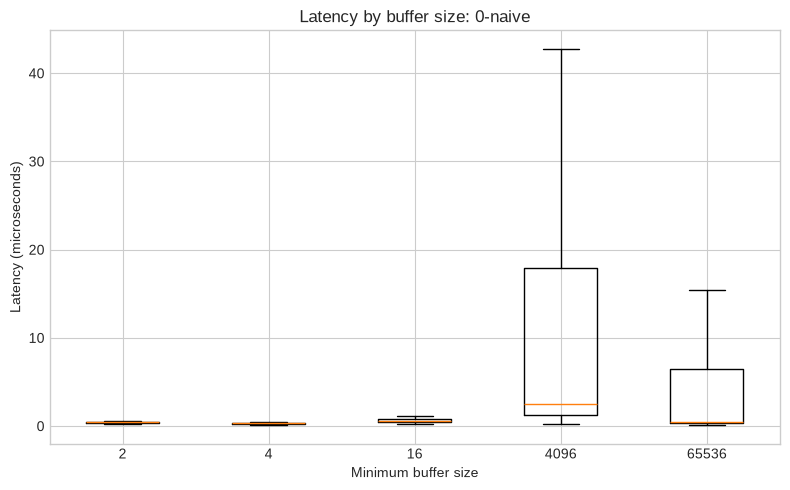

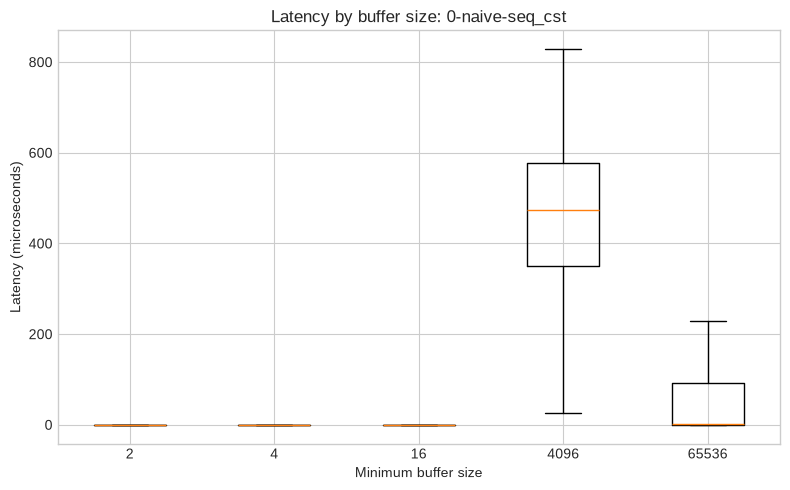

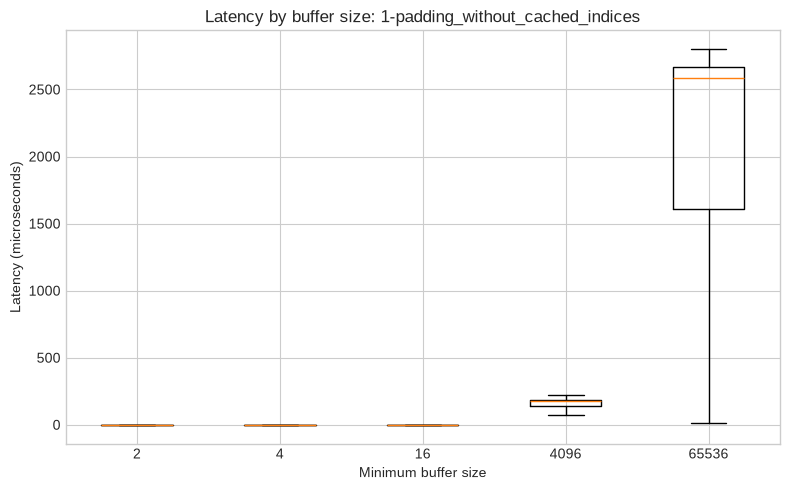

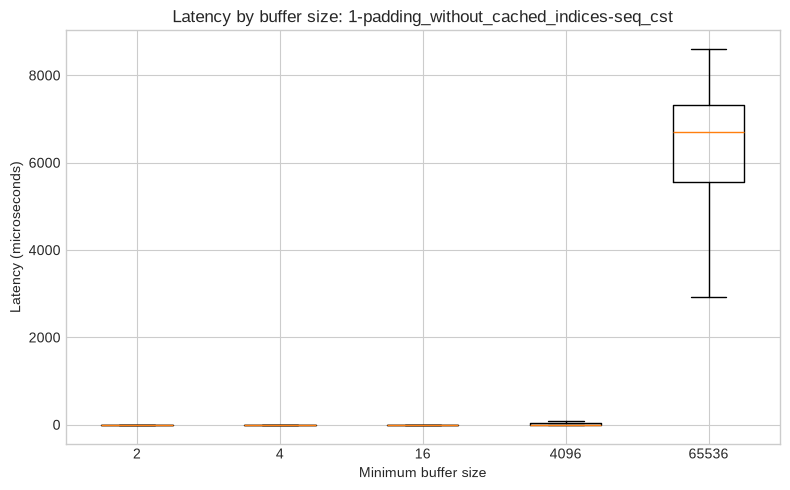

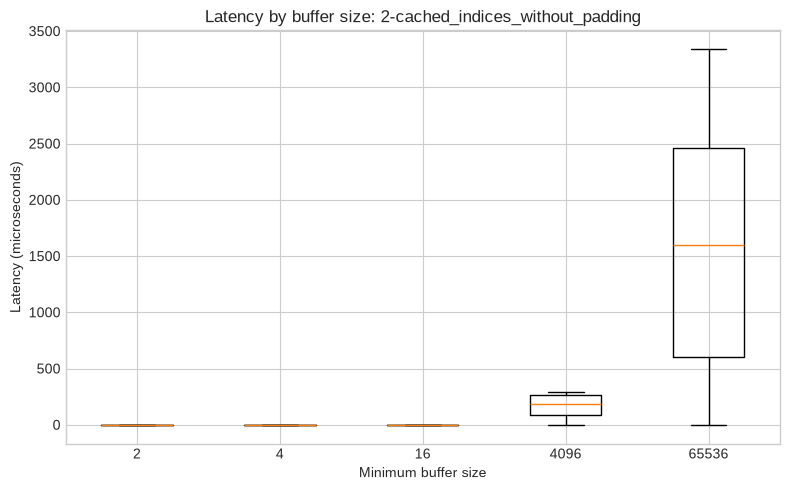

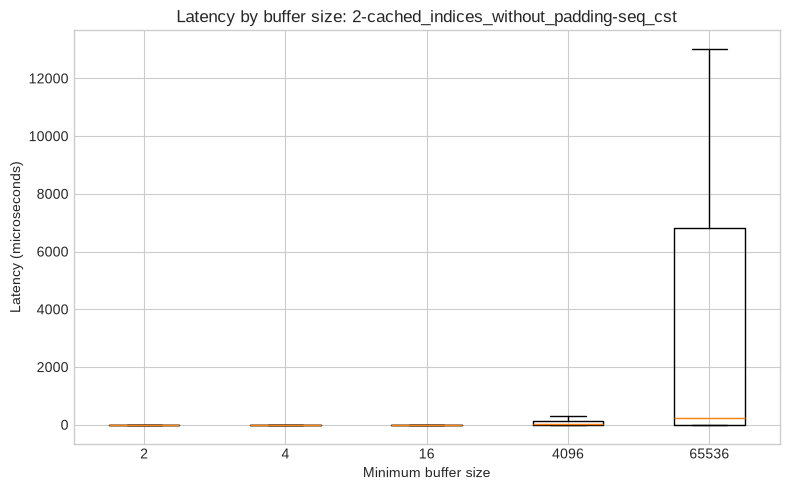

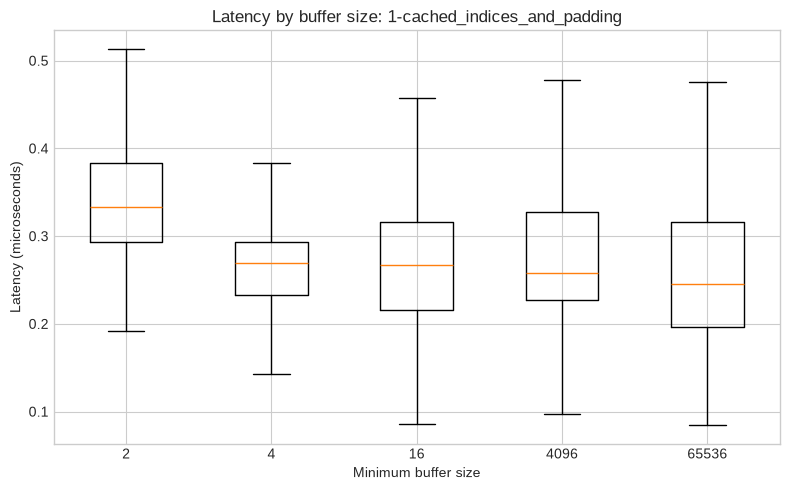

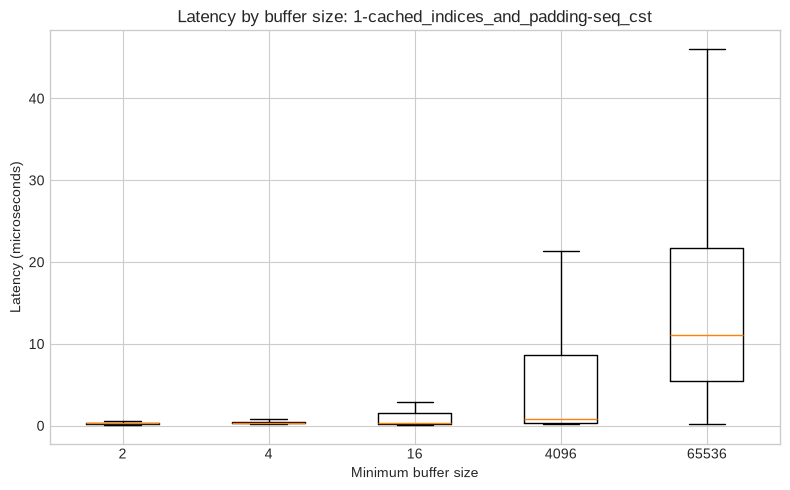

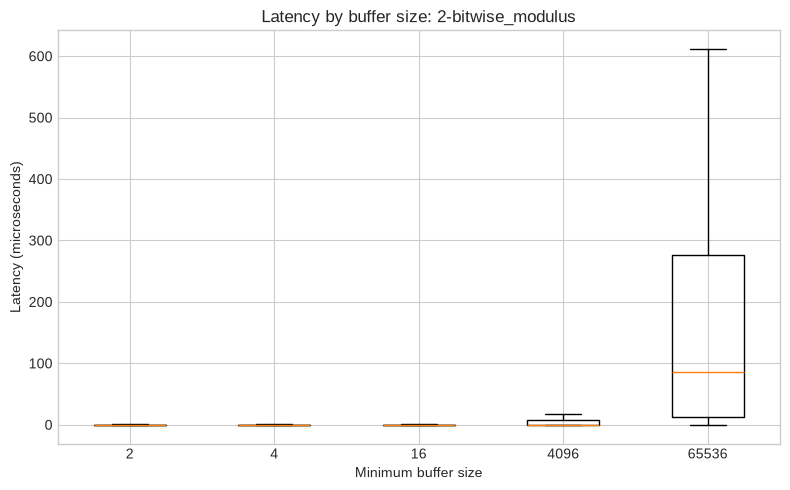

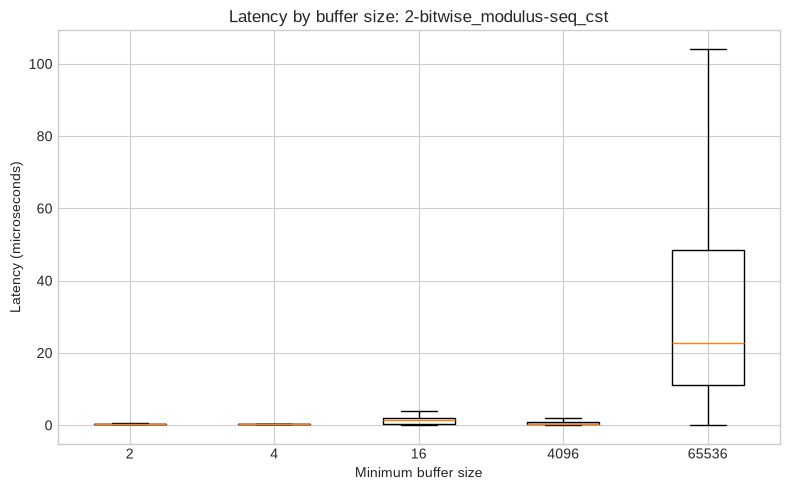

In [6]:
for variant in variant_order:
    subset = latencies[latencies['variant'] == variant]
    sizes = [size for size in available_buffer_sizes if size in subset['buffer_size'].values]
    box_data = [subset.loc[subset['buffer_size'] == size, 'latency_us'] for size in sizes]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.boxplot(box_data, tick_labels=[str(size) for size in sizes], showfliers=False)
    ax.set_title(f'Latency by buffer size: {variant}')
    ax.set_xlabel('Minimum buffer size')
    ax.set_ylabel('Latency (microseconds)')
    plt.tight_layout()
    plt.show()


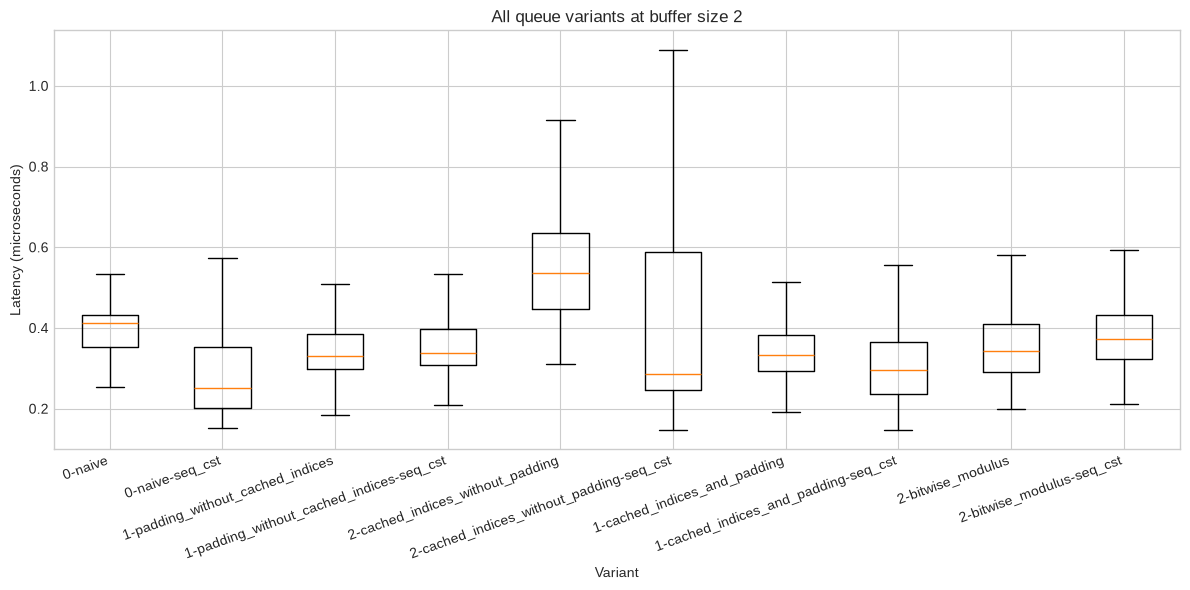

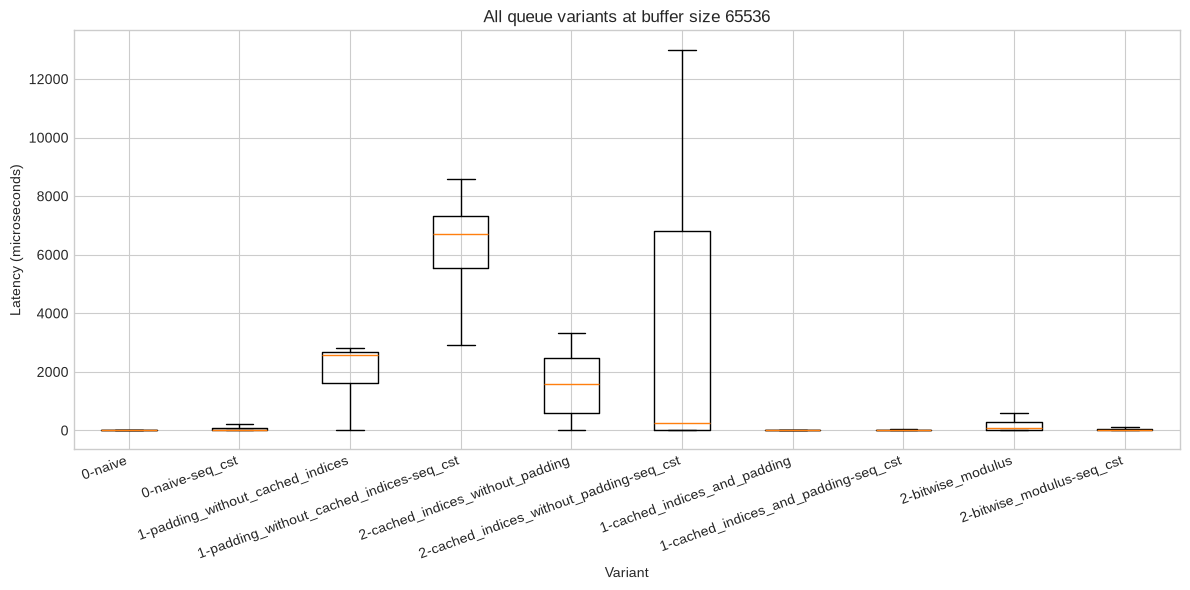

In [7]:
def plot_variant_boxplot(buffer_size, title):
    subset = latencies[latencies['buffer_size'] == buffer_size]
    present_variants = [variant for variant in variant_order if variant in subset['variant'].values]
    box_data = [subset.loc[subset['variant'] == variant, 'latency_us'] for variant in present_variants]

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.boxplot(box_data, tick_labels=present_variants, showfliers=False)
    ax.set_title(title)
    ax.set_xlabel('Variant')
    ax.set_ylabel('Latency (microseconds)')
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.show()

smallest_buffer_size = min(available_buffer_sizes)
largest_buffer_size = max(available_buffer_sizes)
plot_variant_boxplot(smallest_buffer_size, f'All queue variants at buffer size {smallest_buffer_size}')
plot_variant_boxplot(largest_buffer_size, f'All queue variants at buffer size {largest_buffer_size}')


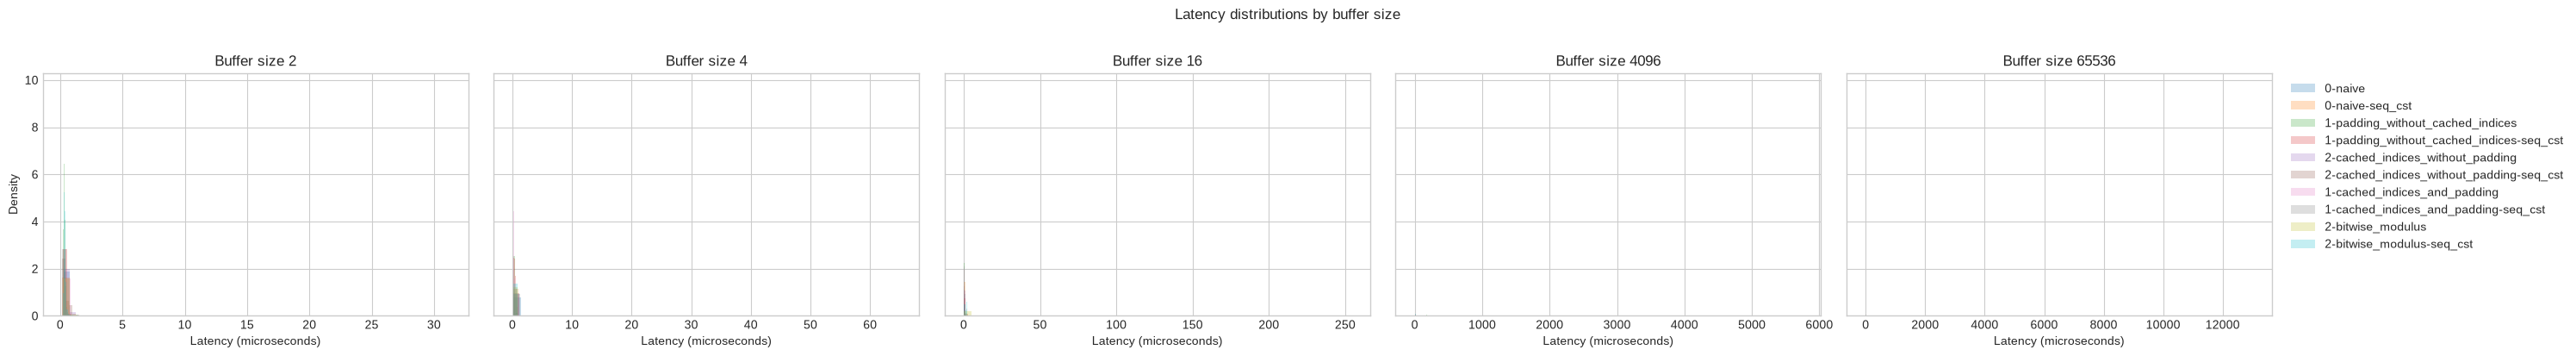

In [8]:
fig, axes = plt.subplots(1, len(available_buffer_sizes), figsize=(6 * len(available_buffer_sizes), 4), sharey=True)
if len(available_buffer_sizes) == 1:
    axes = [axes]

for ax, buffer_size in zip(axes, available_buffer_sizes):
    subset = latencies[latencies['buffer_size'] == buffer_size]
    for variant in variant_order:
        values = subset.loc[subset['variant'] == variant, 'latency_us']
        if len(values) > 0:
            ax.hist(values, bins=50, density=True, alpha=0.25, label=variant)
    ax.set_title(f'Buffer size {buffer_size}')
    ax.set_xlabel('Latency (microseconds)')

axes[0].set_ylabel('Density')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.02, 1))
fig.suptitle('Latency distributions by buffer size', y=1.02)
plt.tight_layout()
plt.show()
